# Flavor Profile vs Sentiment Analysis

This notebook analyzes:
1. Sweet Level vs Sentiment (review-level and product-level)
2. Iced Level vs Sentiment (review-level and product-level)
3. Combined effects of sweet and iced on sentiment

In [2]:
import sys
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Add parent directories to path for imports
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '../..')))
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '..')))

# Set display options
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', 100)
pd.set_option('display.float_format', '{:.3f}'.format)

# Set plot style
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (14, 6)

## 1. Load Data

In [3]:
# Load the sentiment data
df = pd.read_csv('results/getpop_sentiment_reviews.csv')
df = df[df['verified']]

# 1. If sweet_level is not null AND iced_level is null -> set iced_level to 0
df.loc[df['sweet_level'].notna() & df['iced_level'].isna(), 'iced_level'] = 0

# 2. If iced_level is not null AND sweet_level is null -> set sweet_level to 0
df.loc[df['iced_level'].notna() & df['sweet_level'].isna(), 'sweet_level'] = 0


print(f"Total reviews: {len(df)}")
print(f"Reviews with verified=True: {df['verified'].sum()}")
print(f"Reviews with ratings: {df['rating'].notna().sum()}")
print(f"Reviews with sweet_level: {df['sweet_level'].notna().sum()}")
print(f"Reviews with iced_level: {df['iced_level'].notna().sum()}")
print(f"Reviews with both sweet and iced: {(df['sweet_level'].notna() & df['iced_level'].notna()).sum()}")

df.head()

Total reviews: 2927
Reviews with verified=True: 2927
Reviews with ratings: 2927
Reviews with sweet_level: 2410
Reviews with iced_level: 2410
Reviews with both sweet and iced: 2410


,Product,iced_level,sweet_level,rating,Sentiment,Sentiment Score,Site,Review,Product ID,Review ID,verified
0,raz-ca6000-alaskan-mint,4.000,4.000,1.000,neutral,0.594,GETPOP,Way too sweet,1769,318,True
1,hyppe-max-flow-aloe-grape,3.000,3.000,5.000,positive,0.617,GETPOP,Great flavor,1771,10175,True
2,hyppe-max-flow-aloe-grape,NaN,NaN,5.000,neutral,0.398,GETPOP,Perfect,1771,10174,True
3,hyppe-max-flow-aloe-grape,0.000,4.000,5.000,neutral,0.536,GETPOP,Wonderful,1771,10173,True
4,hyde-edge-recharge-aloe-grape,2.000,2.000,4.000,neutral,0.539,GETPOP,Nice smooth flavor,1773,10128,True


## 2. Review-Level Analysis: Sweet Level vs Sentiment

In [4]:
# Filter to reviews with sweet_level
df_sweet = df[df['sweet_level'].notna()].copy()

print(f"\n{'='*70}")
print("REVIEW-LEVEL: Sweet Level vs Sentiment Analysis")
print(f"{'='*70}")
print(f"Total reviews with sweet_level: {len(df_sweet)}")
print(f"\nSweet Level Distribution:")
print(df_sweet['sweet_level'].value_counts().sort_index())
print(f"\nSentiment Distribution:")
counts = (df_sweet['Sentiment'].value_counts())

percentages = df_sweet['Sentiment'].value_counts(normalize=True) * 100

# 3. Combine into a single DataFrame
result = pd.DataFrame({
    'Count': counts,
    'Percentage (%)': percentages.round(2) # Rounding for readability
})
print(result)


REVIEW-LEVEL: Sweet Level vs Sentiment Analysis
Total reviews with sweet_level: 2410

Sweet Level Distribution:
sweet_level
0.000     76
1.000    194
2.000    634
3.000    759
4.000    747
Name: count, dtype: int64

Sentiment Distribution:
           Count  Percentage (%)
Sentiment                       
positive    1603          66.510
neutral      716          29.710
negative      91           3.780


In [5]:
# Calculate mean sentiment score by sweet level
sweet_sentiment = df_sweet.groupby('sweet_level').agg({
    'Sentiment Score': ['mean', 'std', 'count'],
    'rating': 'mean',
    'Sentiment': lambda x: (x == 'positive').sum() / len(x) * 100  # % positive
}).round(3)

sweet_sentiment.columns = ['Sentiment_Score_Mean', 'Sentiment_Score_Std', 'Review_Count', 'Rating_Mean', 'Percent_Positive']
print("\nSweet Level vs Sentiment Metrics:")
print(sweet_sentiment)


Sweet Level vs Sentiment Metrics:
             Sentiment_Score_Mean  Sentiment_Score_Std  Review_Count  \
sweet_level                                                            
0.000                       0.754                0.181            76   
1.000                       0.750                0.184           194   
2.000                       0.760                0.195           634   
3.000                       0.761                0.200           759   
4.000                       0.747                0.207           747   

             Rating_Mean  Percent_Positive  
sweet_level                                 
0.000              4.447            50.000  
1.000              4.490            56.186  
2.000              4.737            64.669  
3.000              4.819            70.751  
4.000              4.878            68.139  


In [6]:
# Statistical test: correlation
corr_sweet_sentiment = df_sweet[['sweet_level', 'Sentiment Score']].corr()
print("\nCorrelation Matrix (Sweet Level vs Sentiment Score):")
print(corr_sweet_sentiment)

# Pearson correlation with p-value
corr_coef, p_value = stats.pearsonr(df_sweet['sweet_level'], df_sweet['Sentiment Score'])
print(f"\nPearson Correlation: {corr_coef:.4f}")
print(f"P-value: {p_value:.4e}")
print(f"Significant at α=0.05: {'Yes' if p_value < 0.05 else 'No'}")


Correlation Matrix (Sweet Level vs Sentiment Score):
                 sweet_level  Sentiment Score
sweet_level            1.000           -0.013
Sentiment Score       -0.013            1.000

Pearson Correlation: -0.0130
P-value: 5.2254e-01
Significant at α=0.05: No


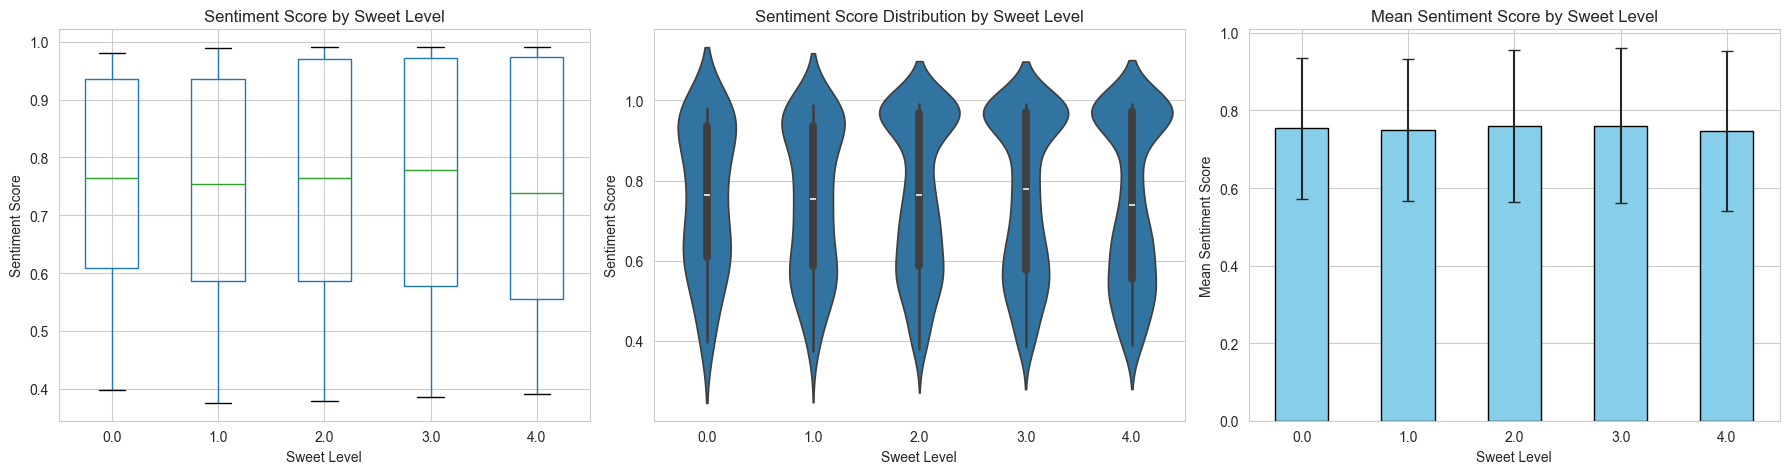

In [7]:
# Visualizations
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Box plot
df_sweet.boxplot(column='Sentiment Score', by='sweet_level', ax=axes[0])
axes[0].set_title('Sentiment Score by Sweet Level')
axes[0].set_xlabel('Sweet Level')
axes[0].set_ylabel('Sentiment Score')
axes[0].get_figure().suptitle('')

# Violin plot
sns.violinplot(data=df_sweet, x='sweet_level', y='Sentiment Score', ax=axes[1])
axes[1].set_title('Sentiment Score Distribution by Sweet Level')
axes[1].set_xlabel('Sweet Level')
axes[1].set_ylabel('Sentiment Score')

# Bar plot with error bars
sweet_sentiment.reset_index().plot(x='sweet_level', y='Sentiment_Score_Mean', 
                                     yerr='Sentiment_Score_Std', kind='bar', ax=axes[2],
                                     capsize=4, color='skyblue', edgecolor='black')
axes[2].set_title('Mean Sentiment Score by Sweet Level')
axes[2].set_xlabel('Sweet Level')
axes[2].set_ylabel('Mean Sentiment Score')
axes[2].set_xticklabels(axes[2].get_xticklabels(), rotation=0)
axes[2].legend().remove()

plt.tight_layout()
plt.show()


Sentiment Distribution (%) by Sweet Level:
Sentiment    negative  neutral  positive
sweet_level                             
0.000          11.840   38.160    50.000
1.000          10.310   33.510    56.190
2.000           4.570   30.760    64.670
3.000           2.770   26.480    70.750
4.000           1.610   30.250    68.140


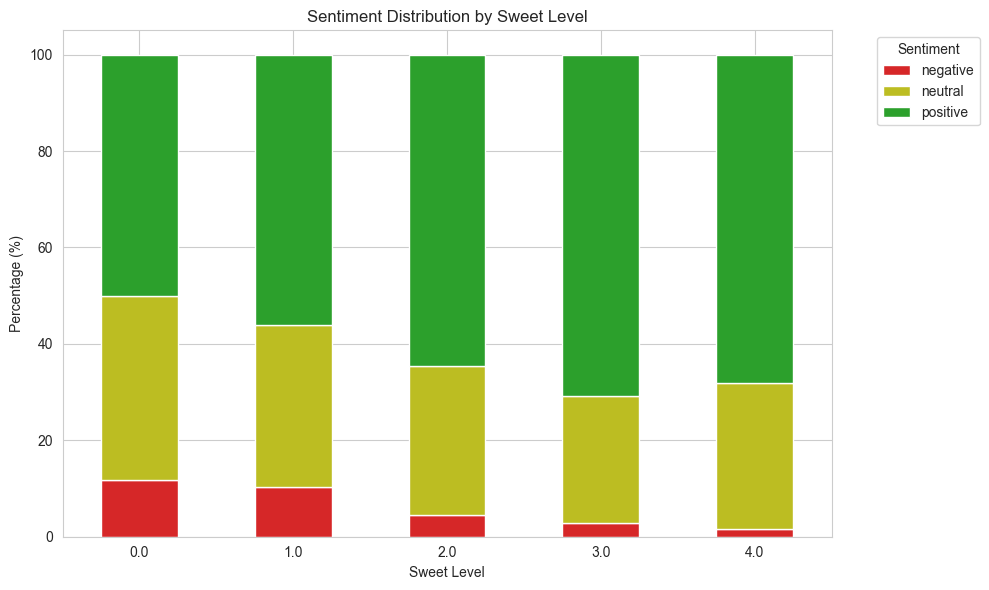

In [8]:
# Sentiment category breakdown by sweet level
sentiment_by_sweet = pd.crosstab(df_sweet['sweet_level'], df_sweet['Sentiment'], normalize='index') * 100
sentiment_by_sweet = sentiment_by_sweet.round(2)

print("\nSentiment Distribution (%) by Sweet Level:")
print(sentiment_by_sweet)

# Visualize
sentiment_by_sweet.plot(kind='bar', stacked=True, figsize=(10, 6), 
                        color=['#d62728', '#bcbd22', '#2ca02c'])
plt.title('Sentiment Distribution by Sweet Level')
plt.xlabel('Sweet Level')
plt.ylabel('Percentage (%)')
plt.legend(title='Sentiment', bbox_to_anchor=(1.05, 1))
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 3. Review-Level Analysis: Iced Level vs Sentiment

In [9]:
# Filter to reviews with iced_level
df_iced = df[df['iced_level'].notna()].copy()

print(f"\n{'='*70}")
print("REVIEW-LEVEL: Iced Level vs Sentiment Analysis")
print(f"{'='*70}")
print(f"Total reviews with iced_level: {len(df_iced)}")
print(f"\nIced Level Distribution:")
print(df_iced['iced_level'].value_counts().sort_index())
print(f"\nSentiment Distribution:")

counts = (df_iced['Sentiment'].value_counts())

percentages = df_iced['Sentiment'].value_counts(normalize=True) * 100

# 3. Combine into a single DataFrame
result = pd.DataFrame({
    'Count': counts,
    'Percentage (%)': percentages.round(2) # Rounding for readability
})
print(result)


REVIEW-LEVEL: Iced Level vs Sentiment Analysis
Total reviews with iced_level: 2410

Iced Level Distribution:
iced_level
0.000    693
1.000    251
2.000    541
3.000    378
4.000    547
Name: count, dtype: int64

Sentiment Distribution:
           Count  Percentage (%)
Sentiment                       
positive    1603          66.510
neutral      716          29.710
negative      91           3.780


In [10]:


print(f"\n{'='*70}")
print("REVIEW-LEVEL: Iced Level vs Sentiment Analysis")
print(f"{'='*70}")
print(f"Total reviews with iced: {len(df_iced)}")
print(f"\Iced Level Distribution:")
print(df_iced['iced_level'].value_counts().sort_index())
print(f"\nSentiment Distribution:")
counts = (df_iced['Sentiment'].value_counts())

percentages = df_iced['Sentiment'].value_counts(normalize=True) * 100

# 3. Combine into a single DataFrame
result = pd.DataFrame({
    'Count': counts,
    'Percentage (%)': percentages.round(2) # Rounding for readability
})
print(result)


REVIEW-LEVEL: Iced Level vs Sentiment Analysis
Total reviews with iced: 2410
\Iced Level Distribution:
iced_level
0.000    693
1.000    251
2.000    541
3.000    378
4.000    547
Name: count, dtype: int64

Sentiment Distribution:
           Count  Percentage (%)
Sentiment                       
positive    1603          66.510
neutral      716          29.710
negative      91           3.780


In [11]:
# Sentiment category breakdown by sweet level
sentiment_by_iced = pd.crosstab(df_sweet['iced_level'], df_sweet['Sentiment'], normalize='index') * 100
sentiment_by_iced = sentiment_by_iced.round(2)

print("\nSentiment Distribution (%) by Iced Level:")
print(sentiment_by_iced)



Sentiment Distribution (%) by Iced Level:
Sentiment   negative  neutral  positive
iced_level                             
0.000          2.450   26.260    71.280
1.000          4.780   33.070    62.150
2.000          5.180   31.420    63.400
3.000          3.970   29.630    66.400
4.000          3.470   30.900    65.630


In [12]:
# Calculate mean sentiment score by iced level
iced_sentiment = df_iced.groupby('iced_level').agg({
    'Sentiment Score': ['mean', 'std', 'count'],
    'rating': 'mean',
    'Sentiment': lambda x: (x == 'positive').sum() / len(x) * 100
}).round(3)

iced_sentiment.columns = ['Sentiment_Score_Mean', 'Sentiment_Score_Std', 'Review_Count', 'Rating_Mean', 'Percent_Positive']
print("\nIced Level vs Sentiment Metrics:")
print(iced_sentiment)


Iced Level vs Sentiment Metrics:
            Sentiment_Score_Mean  Sentiment_Score_Std  Review_Count  \
iced_level                                                            
0.000                      0.781                0.194           693   
1.000                      0.737                0.202           251   
2.000                      0.759                0.197           541   
3.000                      0.747                0.202           378   
4.000                      0.733                0.203           547   

            Rating_Mean  Percent_Positive  
iced_level                                 
0.000             4.827            71.284  
1.000             4.606            62.151  
2.000             4.708            63.401  
3.000             4.788            66.402  
4.000             4.856            65.631  


In [13]:
# Statistical test: correlation
corr_iced_sentiment = df_iced[['iced_level', 'Sentiment Score']].corr()
print("\nCorrelation Matrix (Iced Level vs Sentiment Score):")
print(corr_iced_sentiment)

# Pearson correlation with p-value
corr_coef, p_value = stats.pearsonr(df_iced['iced_level'], df_iced['Sentiment Score'])
print(f"\nPearson Correlation: {corr_coef:.4f}")
print(f"P-value: {p_value:.4e}")
print(f"Significant at α=0.05: {'Yes' if p_value < 0.05 else 'No'}")


Correlation Matrix (Iced Level vs Sentiment Score):
                 iced_level  Sentiment Score
iced_level            1.000           -0.081
Sentiment Score      -0.081            1.000

Pearson Correlation: -0.0810
P-value: 6.9200e-05
Significant at α=0.05: Yes


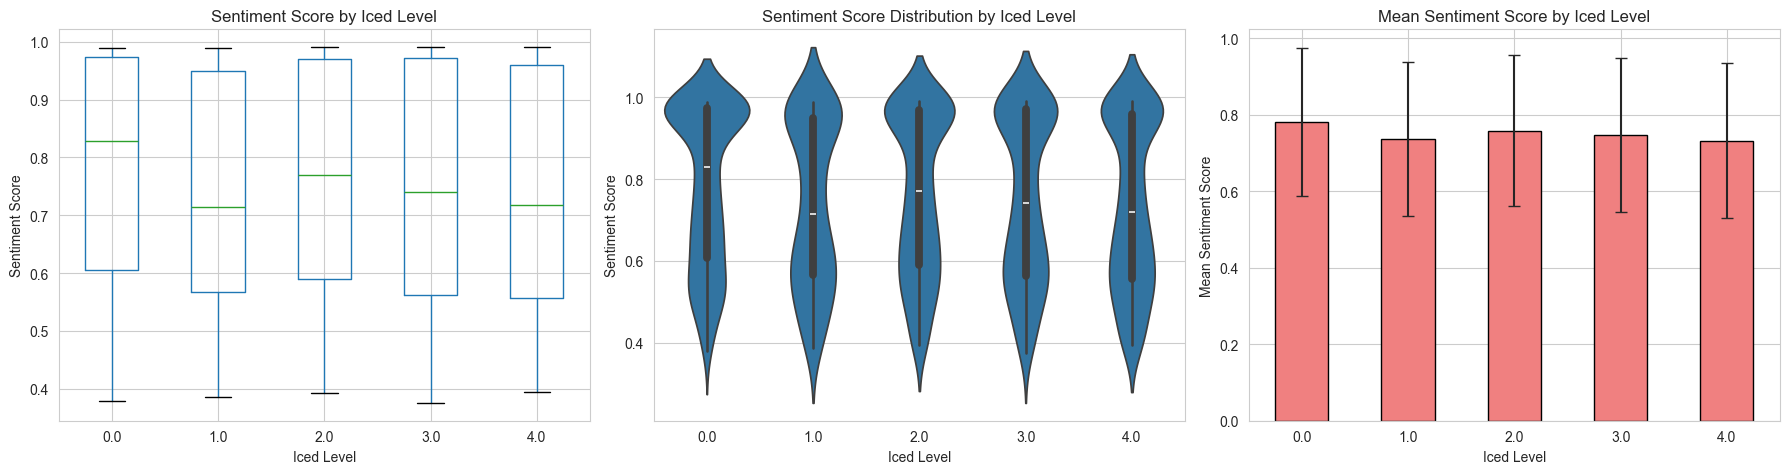

In [14]:
# Visualizations
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Box plot
df_iced.boxplot(column='Sentiment Score', by='iced_level', ax=axes[0])
axes[0].set_title('Sentiment Score by Iced Level')
axes[0].set_xlabel('Iced Level')
axes[0].set_ylabel('Sentiment Score')
axes[0].get_figure().suptitle('')

# Violin plot
sns.violinplot(data=df_iced, x='iced_level', y='Sentiment Score', ax=axes[1])
axes[1].set_title('Sentiment Score Distribution by Iced Level')
axes[1].set_xlabel('Iced Level')
axes[1].set_ylabel('Sentiment Score')

# Bar plot with error bars
iced_sentiment.reset_index().plot(x='iced_level', y='Sentiment_Score_Mean', 
                                   yerr='Sentiment_Score_Std', kind='bar', ax=axes[2],
                                   capsize=4, color='lightcoral', edgecolor='black')
axes[2].set_title('Mean Sentiment Score by Iced Level')
axes[2].set_xlabel('Iced Level')
axes[2].set_ylabel('Mean Sentiment Score')
axes[2].set_xticklabels(axes[2].get_xticklabels(), rotation=0)
axes[2].legend().remove()

plt.tight_layout()
plt.show()


Sentiment Distribution (%) by Iced Level:
Sentiment   negative  neutral  positive
iced_level                             
0.000          2.450   26.260    71.280
1.000          4.780   33.070    62.150
2.000          5.180   31.420    63.400
3.000          3.970   29.630    66.400
4.000          3.470   30.900    65.630


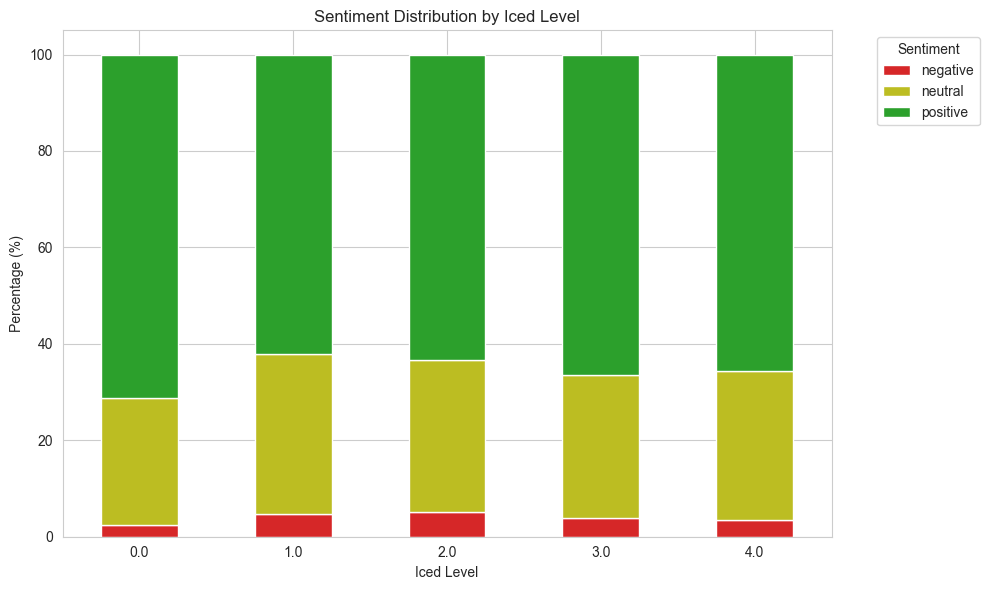

In [15]:
# Sentiment category breakdown by iced level
sentiment_by_iced = pd.crosstab(df_iced['iced_level'], df_iced['Sentiment'], normalize='index') * 100
sentiment_by_iced = sentiment_by_iced.round(2)

print("\nSentiment Distribution (%) by Iced Level:")
print(sentiment_by_iced)

# Visualize
sentiment_by_iced.plot(kind='bar', stacked=True, figsize=(10, 6),
                       color=['#d62728', '#bcbd22', '#2ca02c'])
plt.title('Sentiment Distribution by Iced Level')
plt.xlabel('Iced Level')
plt.ylabel('Percentage (%)')
plt.legend(title='Sentiment', bbox_to_anchor=(1.05, 1))
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 4. Product-Level Analysis: Sweet Level vs Sentiment

In [16]:
# Aggregate to product level for sweet
product_sweet = df_sweet.groupby('Product ID').agg({
    'sweet_level': 'mean',
    'Sentiment Score': 'mean',
    'rating': 'mean',
    'Review': 'count',
    'Product': 'first'
}).round(3)

product_sweet.columns = ['Sweet_Level_Avg', 'Sentiment_Score_Avg', 'Rating_Avg', 'Review_Count', 'Product_Name']
product_sweet = product_sweet.reset_index()

print(f"\n{'='*70}")
print("PRODUCT-LEVEL: Sweet Level vs Sentiment Analysis")
print(f"{'='*70}")
print(f"Total products: {len(product_sweet)}")
print(f"\nProducts by review count:")
print(product_sweet['Review_Count'].describe())

product_sweet.head(10)


PRODUCT-LEVEL: Sweet Level vs Sentiment Analysis
Total products: 1081

Products by review count:
count   1081.000
mean       2.228
std        2.346
min        0.000
25%        1.000
50%        1.000
75%        2.000
max       21.000
Name: Review_Count, dtype: float64


,Product ID,Sweet_Level_Avg,Sentiment_Score_Avg,Rating_Avg,Review_Count,Product_Name
0,1769,4.000,0.594,1.000,1,raz-ca6000-alaskan-mint
1,1771,3.500,0.576,5.000,2,hyppe-max-flow-aloe-grape
2,1773,2.000,0.539,4.000,1,hyde-edge-recharge-aloe-grape
3,1783,3.000,0.974,4.000,1,fume-ultra-apple-candy
4,1794,2.000,0.487,3.000,1,tyson-2-0-legend-30k-apple-melonberry
5,1814,2.000,0.987,5.000,1,geek-bar-pulse-x-25k-atl-mint
6,1819,4.000,0.398,5.000,1,geek-bar-pulse-15000-blow-pop-1
7,1822,2.333,0.611,4.667,6,hyde-edge-recharge-banana-ice
8,1830,3.000,0.584,5.000,5,hyde-edge-recharge-blueberry
9,1836,2.615,0.845,5.000,13,hyde-edge-recharge-cola-ice


In [17]:
# Correlation at product level
corr_product_sweet = product_sweet[['Sweet_Level_Avg', 'Sentiment_Score_Avg', 'Rating_Avg']].corr()
print("\nProduct-Level Correlation Matrix (Sweet):")
print(corr_product_sweet)

# Statistical test
corr_coef, p_value = stats.pearsonr(product_sweet['Sweet_Level_Avg'], product_sweet['Sentiment_Score_Avg'])
print(f"\nPearson Correlation (Sweet vs Sentiment): {corr_coef:.4f}")
print(f"P-value: {p_value:.4e}")
print(f"Significant at α=0.05: {'Yes' if p_value < 0.05 else 'No'}")


Product-Level Correlation Matrix (Sweet):
                     Sweet_Level_Avg  Sentiment_Score_Avg  Rating_Avg
Sweet_Level_Avg                1.000               -0.026       0.232
Sentiment_Score_Avg           -0.026                1.000       0.028
Rating_Avg                     0.232                0.028       1.000

Pearson Correlation (Sweet vs Sentiment): -0.0262
P-value: 3.8924e-01
Significant at α=0.05: No


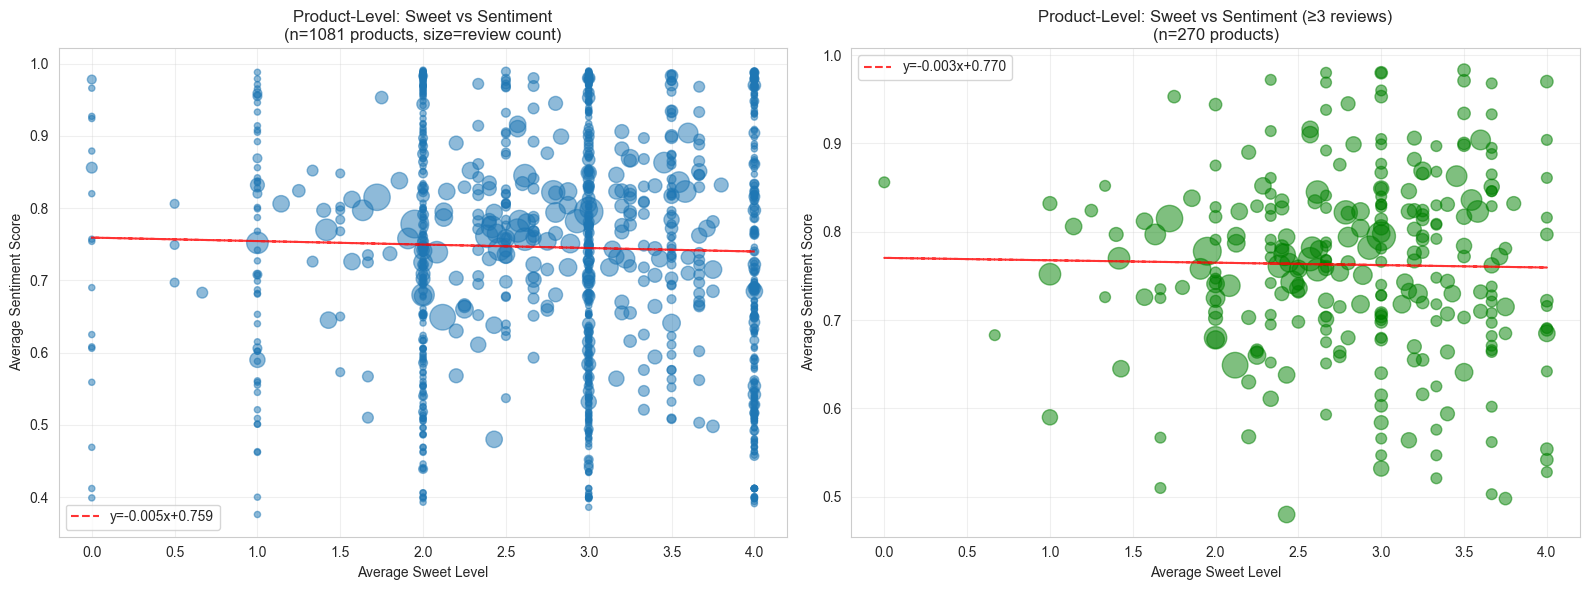


Filtered (≥3 reviews) Correlation: -0.0185, p=7.6213e-01


In [18]:
# Scatter plot with regression line
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# All products
axes[0].scatter(product_sweet['Sweet_Level_Avg'], product_sweet['Sentiment_Score_Avg'], 
                alpha=0.5, s=product_sweet['Review_Count']*20)
axes[0].set_xlabel('Average Sweet Level')
axes[0].set_ylabel('Average Sentiment Score')
axes[0].set_title(f'Product-Level: Sweet vs Sentiment\n(n={len(product_sweet)} products, size=review count)')
# Add regression line
z = np.polyfit(product_sweet['Sweet_Level_Avg'], product_sweet['Sentiment_Score_Avg'], 1)
p = np.poly1d(z)
axes[0].plot(product_sweet['Sweet_Level_Avg'], p(product_sweet['Sweet_Level_Avg']), 
             "r--", alpha=0.8, label=f'y={z[0]:.3f}x+{z[1]:.3f}')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Products with 3+ reviews only
product_sweet_filtered = product_sweet[product_sweet['Review_Count'] >= 3]
axes[1].scatter(product_sweet_filtered['Sweet_Level_Avg'], product_sweet_filtered['Sentiment_Score_Avg'],
                alpha=0.5, s=product_sweet_filtered['Review_Count']*20, color='green')
axes[1].set_xlabel('Average Sweet Level')
axes[1].set_ylabel('Average Sentiment Score')
axes[1].set_title(f'Product-Level: Sweet vs Sentiment (≥3 reviews)\n(n={len(product_sweet_filtered)} products)')
if len(product_sweet_filtered) > 1:
    z = np.polyfit(product_sweet_filtered['Sweet_Level_Avg'], product_sweet_filtered['Sentiment_Score_Avg'], 1)
    p = np.poly1d(z)
    axes[1].plot(product_sweet_filtered['Sweet_Level_Avg'], p(product_sweet_filtered['Sweet_Level_Avg']),
                 "r--", alpha=0.8, label=f'y={z[0]:.3f}x+{z[1]:.3f}')
    axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

if len(product_sweet_filtered) > 1:
    corr_coef_filt, p_value_filt = stats.pearsonr(product_sweet_filtered['Sweet_Level_Avg'], 
                                                    product_sweet_filtered['Sentiment_Score_Avg'])
    print(f"\nFiltered (≥3 reviews) Correlation: {corr_coef_filt:.4f}, p={p_value_filt:.4e}")

## 5. Product-Level Analysis: Iced Level vs Sentiment

In [19]:
# Aggregate to product level for iced
product_iced = df_iced.groupby('Product ID').agg({
    'iced_level': 'mean',
    'Sentiment Score': 'mean',
    'rating': 'mean',
    'Review': 'count',
    'Product': 'first'
}).round(3)

product_iced.columns = ['Iced_Level_Avg', 'Sentiment_Score_Avg', 'Rating_Avg', 'Review_Count', 'Product_Name']
product_iced = product_iced.reset_index()

print(f"\n{'='*70}")
print("PRODUCT-LEVEL: Iced Level vs Sentiment Analysis")
print(f"{'='*70}")
print(f"Total products: {len(product_iced)}")
print(f"\nProducts by review count:")
print(product_iced['Review_Count'].describe())

product_iced.head(10)


PRODUCT-LEVEL: Iced Level vs Sentiment Analysis
Total products: 1081

Products by review count:
count   1081.000
mean       2.228
std        2.346
min        0.000
25%        1.000
50%        1.000
75%        2.000
max       21.000
Name: Review_Count, dtype: float64


,Product ID,Iced_Level_Avg,Sentiment_Score_Avg,Rating_Avg,Review_Count,Product_Name
0,1769,4.000,0.594,1.000,1,raz-ca6000-alaskan-mint
1,1771,1.500,0.576,5.000,2,hyppe-max-flow-aloe-grape
2,1773,2.000,0.539,4.000,1,hyde-edge-recharge-aloe-grape
3,1783,2.000,0.974,4.000,1,fume-ultra-apple-candy
4,1794,0.000,0.487,3.000,1,tyson-2-0-legend-30k-apple-melonberry
5,1814,2.000,0.987,5.000,1,geek-bar-pulse-x-25k-atl-mint
6,1819,0.000,0.398,5.000,1,geek-bar-pulse-15000-blow-pop-1
7,1822,2.667,0.611,4.667,6,hyde-edge-recharge-banana-ice
8,1830,1.400,0.584,5.000,5,hyde-edge-recharge-blueberry
9,1836,2.538,0.845,5.000,13,hyde-edge-recharge-cola-ice


In [20]:
# Correlation at product level
corr_product_iced = product_iced[['Iced_Level_Avg', 'Sentiment_Score_Avg', 'Rating_Avg']].corr()
print("\nProduct-Level Correlation Matrix (Iced):")
print(corr_product_iced)

# Statistical test
corr_coef, p_value = stats.pearsonr(product_iced['Iced_Level_Avg'], product_iced['Sentiment_Score_Avg'])
print(f"\nPearson Correlation (Iced vs Sentiment): {corr_coef:.4f}")
print(f"P-value: {p_value:.4e}")
print(f"Significant at α=0.05: {'Yes' if p_value < 0.05 else 'No'}")


Product-Level Correlation Matrix (Iced):
                     Iced_Level_Avg  Sentiment_Score_Avg  Rating_Avg
Iced_Level_Avg                1.000               -0.083       0.026
Sentiment_Score_Avg          -0.083                1.000       0.028
Rating_Avg                    0.026                0.028       1.000

Pearson Correlation (Iced vs Sentiment): -0.0826
P-value: 6.5551e-03
Significant at α=0.05: Yes


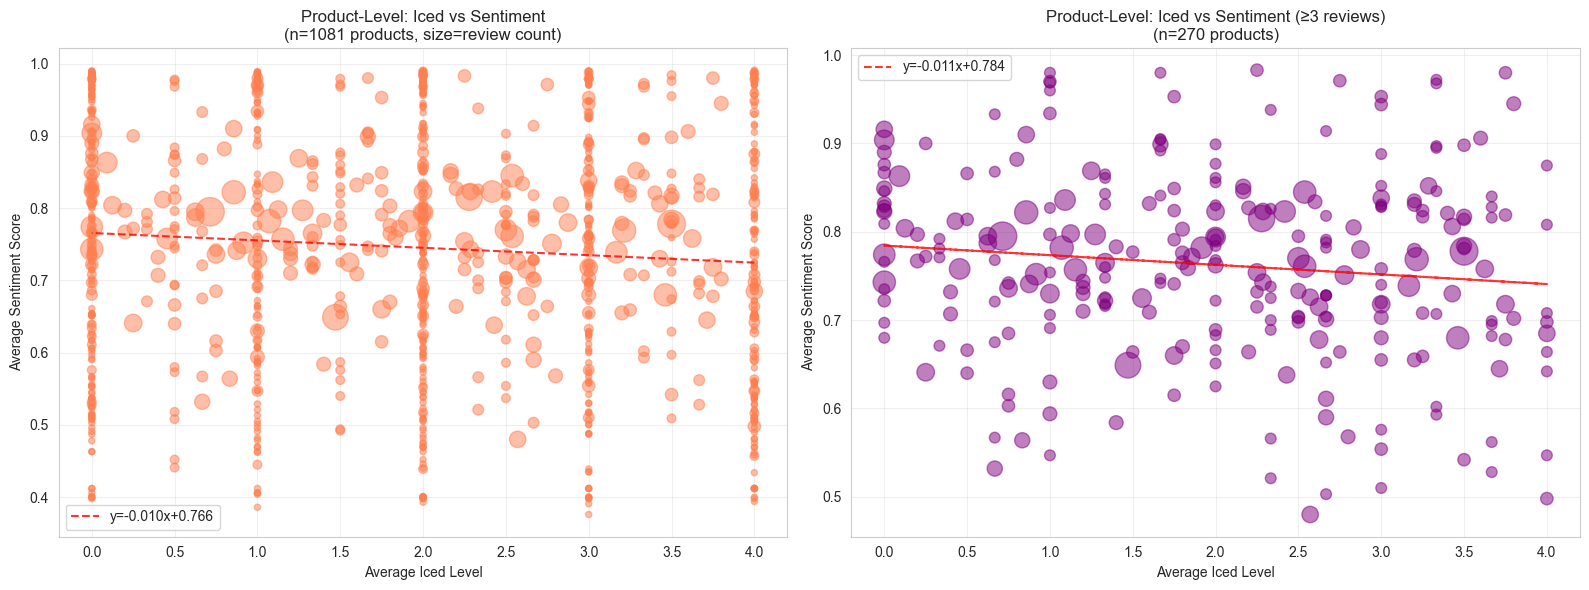


Filtered (≥3 reviews) Correlation: -0.1215, p=4.6175e-02


In [21]:
# Scatter plot with regression line
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# All products
axes[0].scatter(product_iced['Iced_Level_Avg'], product_iced['Sentiment_Score_Avg'],
                alpha=0.5, s=product_iced['Review_Count']*20, color='coral')
axes[0].set_xlabel('Average Iced Level')
axes[0].set_ylabel('Average Sentiment Score')
axes[0].set_title(f'Product-Level: Iced vs Sentiment\n(n={len(product_iced)} products, size=review count)')
# Add regression line
z = np.polyfit(product_iced['Iced_Level_Avg'], product_iced['Sentiment_Score_Avg'], 1)
p = np.poly1d(z)
axes[0].plot(product_iced['Iced_Level_Avg'], p(product_iced['Iced_Level_Avg']),
             "r--", alpha=0.8, label=f'y={z[0]:.3f}x+{z[1]:.3f}')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Products with 3+ reviews only
product_iced_filtered = product_iced[product_iced['Review_Count'] >= 3]
axes[1].scatter(product_iced_filtered['Iced_Level_Avg'], product_iced_filtered['Sentiment_Score_Avg'],
                alpha=0.5, s=product_iced_filtered['Review_Count']*20, color='purple')
axes[1].set_xlabel('Average Iced Level')
axes[1].set_ylabel('Average Sentiment Score')
axes[1].set_title(f'Product-Level: Iced vs Sentiment (≥3 reviews)\n(n={len(product_iced_filtered)} products)')
if len(product_iced_filtered) > 1:
    z = np.polyfit(product_iced_filtered['Iced_Level_Avg'], product_iced_filtered['Sentiment_Score_Avg'], 1)
    p = np.poly1d(z)
    axes[1].plot(product_iced_filtered['Iced_Level_Avg'], p(product_iced_filtered['Iced_Level_Avg']),
                 "r--", alpha=0.8, label=f'y={z[0]:.3f}x+{z[1]:.3f}')
    axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

if len(product_iced_filtered) > 1:
    corr_coef_filt, p_value_filt = stats.pearsonr(product_iced_filtered['Iced_Level_Avg'],
                                                    product_iced_filtered['Sentiment_Score_Avg'])
    print(f"\nFiltered (≥3 reviews) Correlation: {corr_coef_filt:.4f}, p={p_value_filt:.4e}")

## 6. Combined Analysis: Sweet + Iced Interaction

In [22]:
# Reviews with both sweet and iced levels
df_both = df[(df['sweet_level'].notna()) & (df['iced_level'].notna())].copy()

print(f"\n{'='*70}")
print("COMBINED: Sweet + Iced vs Sentiment")
print(f"{'='*70}")
print(f"Total reviews with both sweet and iced: {len(df_both)}")

# Correlation matrix
corr_combined = df_both[['sweet_level', 'iced_level', 'Sentiment Score', 'rating']].corr()
print("\nCorrelation Matrix:")
print(corr_combined)


COMBINED: Sweet + Iced vs Sentiment
Total reviews with both sweet and iced: 2410

Correlation Matrix:
                 sweet_level  iced_level  Sentiment Score  rating
sweet_level            1.000       0.099           -0.013   0.173
iced_level             0.099       1.000           -0.081   0.027
Sentiment Score       -0.013      -0.081            1.000   0.070
rating                 0.173       0.027            0.070   1.000


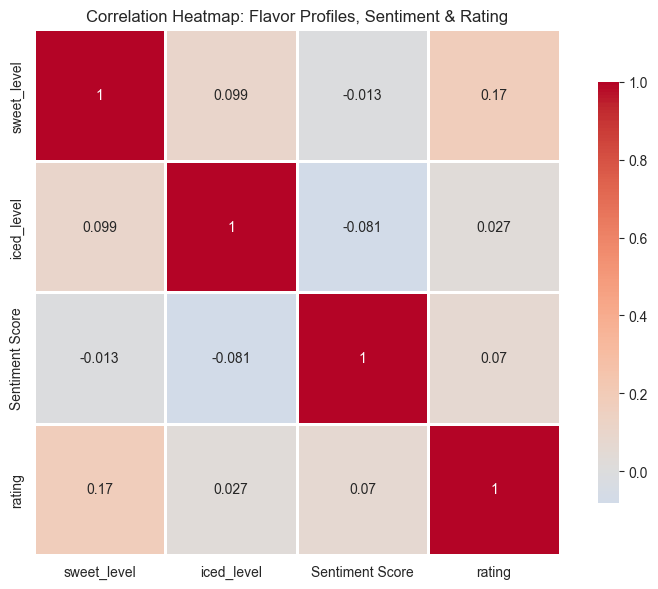

In [23]:
# Heatmap of correlations
plt.figure(figsize=(8, 6))
sns.heatmap(corr_combined, annot=True, cmap='coolwarm', center=0, 
            square=True, linewidths=1, cbar_kws={"shrink": 0.8})
plt.title('Correlation Heatmap: Flavor Profiles, Sentiment & Rating')
plt.tight_layout()
plt.show()

In [24]:
# Create flavor profile segments
df_both['flavor_profile'] = pd.cut(df_both['sweet_level'], bins=[0, 2, 4], labels=['Low Sweet', 'High Sweet']).astype(str) + ' / ' + \
                             pd.cut(df_both['iced_level'], bins=[0, 2, 4], labels=['Low Iced', 'High Iced']).astype(str)

# Sentiment by flavor profile
flavor_sentiment = df_both.groupby('flavor_profile').agg({
    'Sentiment Score': ['mean', 'std', 'count'],
    'rating': 'mean'
}).round(3)

flavor_sentiment.columns = ['Sentiment_Mean', 'Sentiment_Std', 'Count', 'Rating_Mean']
print("\nSentiment by Flavor Profile:")
print(flavor_sentiment)


Sentiment by Flavor Profile:
                        Sentiment_Mean  Sentiment_Std  Count  Rating_Mean
flavor_profile                                                           
High Sweet / High Iced           0.726          0.207    659        4.882
High Sweet / Low Iced            0.760          0.202    404        4.755
Low Sweet / High Iced            0.768          0.190    222        4.739
Low Sweet / Low Iced             0.745          0.196    356        4.610


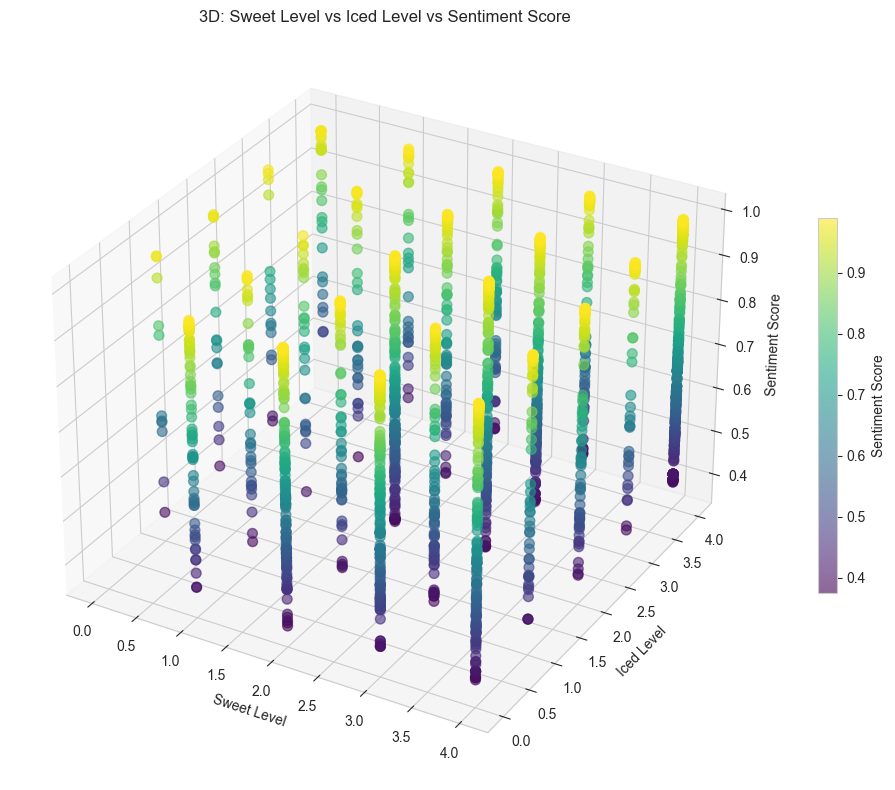

In [25]:
# 3D scatter plot
from mpl_toolkits.mplot3d import Axes3D

fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection='3d')

scatter = ax.scatter(df_both['sweet_level'], df_both['iced_level'], df_both['Sentiment Score'],
                     c=df_both['Sentiment Score'], cmap='viridis', alpha=0.6, s=50)

ax.set_xlabel('Sweet Level')
ax.set_ylabel('Iced Level')
ax.set_zlabel('Sentiment Score')
ax.set_title('3D: Sweet Level vs Iced Level vs Sentiment Score')
plt.colorbar(scatter, label='Sentiment Score', shrink=0.5)
plt.tight_layout()
plt.show()

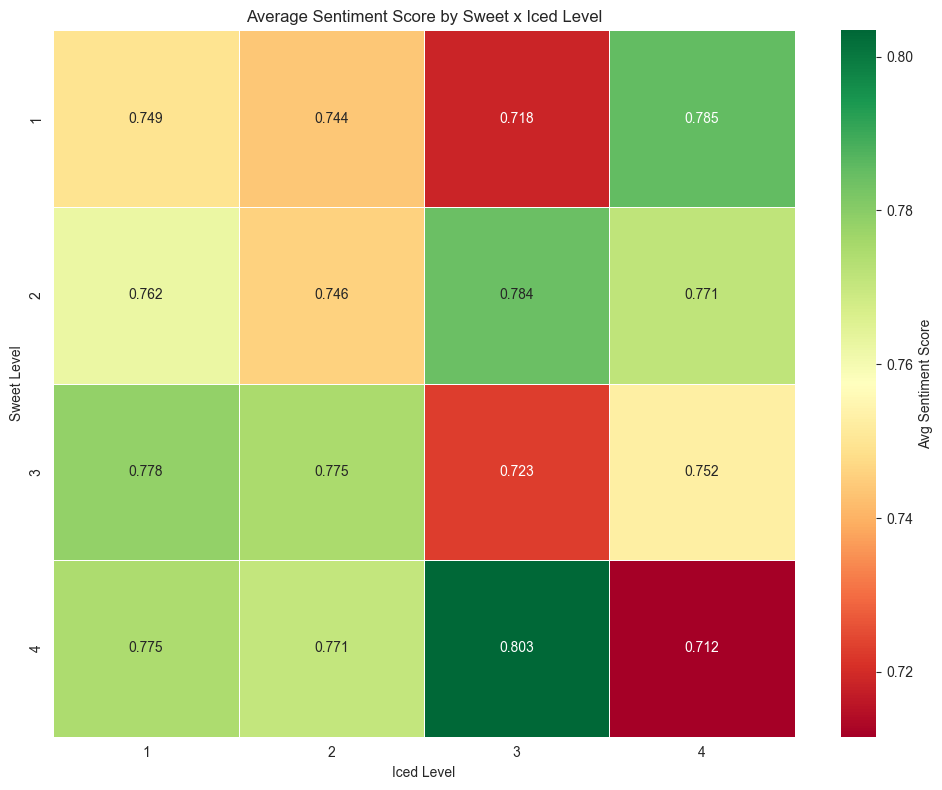

In [26]:
# 2D heatmap: average sentiment by sweet x iced bins
df_both['sweet_bin'] = pd.cut(df_both['sweet_level'], bins=4, labels=['1', '2', '3', '4'])
df_both['iced_bin'] = pd.cut(df_both['iced_level'], bins=4, labels=['1', '2', '3', '4'])

pivot_sentiment = df_both.pivot_table(values='Sentiment Score', 
                                       index='sweet_bin', 
                                       columns='iced_bin', 
                                       aggfunc='mean')

plt.figure(figsize=(10, 8))
sns.heatmap(pivot_sentiment, annot=True, fmt='.3f', cmap='RdYlGn', 
            cbar_kws={'label': 'Avg Sentiment Score'}, linewidths=0.5)
plt.title('Average Sentiment Score by Sweet x Iced Level')
plt.xlabel('Iced Level')
plt.ylabel('Sweet Level')
plt.tight_layout()
plt.show()

## 7. Statistical Summary and Key Findings

In [27]:
print("\n" + "="*80)
print("SUMMARY OF KEY FINDINGS")
print("="*80)

print("\n1. REVIEW-LEVEL ANALYSIS")
print("-" * 40)

# Sweet
corr_sweet_rev, p_sweet_rev = stats.pearsonr(df_sweet['sweet_level'], df_sweet['Sentiment Score'])
print(f"Sweet vs Sentiment:")
print(f"  - Correlation: {corr_sweet_rev:.4f} (p={p_sweet_rev:.4e})")
print(f"  - Sample size: {len(df_sweet)} reviews")
print(f"  - Interpretation: {'Significant' if p_sweet_rev < 0.05 else 'Not significant'}")

# Iced
corr_iced_rev, p_iced_rev = stats.pearsonr(df_iced['iced_level'], df_iced['Sentiment Score'])
print(f"\nIced vs Sentiment:")
print(f"  - Correlation: {corr_iced_rev:.4f} (p={p_iced_rev:.4e})")
print(f"  - Sample size: {len(df_iced)} reviews")
print(f"  - Interpretation: {'Significant' if p_iced_rev < 0.05 else 'Not significant'}")

print("\n2. PRODUCT-LEVEL ANALYSIS")
print("-" * 40)

# Sweet
corr_sweet_prod, p_sweet_prod = stats.pearsonr(product_sweet['Sweet_Level_Avg'], product_sweet['Sentiment_Score_Avg'])
print(f"Sweet vs Sentiment:")
print(f"  - Correlation: {corr_sweet_prod:.4f} (p={p_sweet_prod:.4e})")
print(f"  - Sample size: {len(product_sweet)} products")
print(f"  - Interpretation: {'Significant' if p_sweet_prod < 0.05 else 'Not significant'}")

# Iced
corr_iced_prod, p_iced_prod = stats.pearsonr(product_iced['Iced_Level_Avg'], product_iced['Sentiment_Score_Avg'])
print(f"\nIced vs Sentiment:")
print(f"  - Correlation: {corr_iced_prod:.4f} (p={p_iced_prod:.4e})")
print(f"  - Sample size: {len(product_iced)} products")
print(f"  - Interpretation: {'Significant' if p_iced_prod < 0.05 else 'Not significant'}")

print("\n3. COMBINED EFFECTS")
print("-" * 40)
print(f"Reviews with both sweet and iced: {len(df_both)}")
print(f"\nCorrelation summary:")
print(f"  - Sweet ↔ Iced: {corr_combined.loc['sweet_level', 'iced_level']:.4f}")
print(f"  - Sweet ↔ Sentiment: {corr_combined.loc['sweet_level', 'Sentiment Score']:.4f}")
print(f"  - Iced ↔ Sentiment: {corr_combined.loc['iced_level', 'Sentiment Score']:.4f}")
print(f"  - Rating ↔ Sentiment: {corr_combined.loc['rating', 'Sentiment Score']:.4f}")

print("\n" + "="*80)


SUMMARY OF KEY FINDINGS

1. REVIEW-LEVEL ANALYSIS
----------------------------------------
Sweet vs Sentiment:
  - Correlation: -0.0130 (p=5.2254e-01)
  - Sample size: 2410 reviews
  - Interpretation: Not significant

Iced vs Sentiment:
  - Correlation: -0.0810 (p=6.9200e-05)
  - Sample size: 2410 reviews
  - Interpretation: Significant

2. PRODUCT-LEVEL ANALYSIS
----------------------------------------
Sweet vs Sentiment:
  - Correlation: -0.0262 (p=3.8924e-01)
  - Sample size: 1081 products
  - Interpretation: Not significant

Iced vs Sentiment:
  - Correlation: -0.0826 (p=6.5551e-03)
  - Sample size: 1081 products
  - Interpretation: Significant

3. COMBINED EFFECTS
----------------------------------------
Reviews with both sweet and iced: 2410

Correlation summary:
  - Sweet ↔ Iced: 0.0995
  - Sweet ↔ Sentiment: -0.0130
  - Iced ↔ Sentiment: -0.0810
  - Rating ↔ Sentiment: 0.0696



## 8. Export Results

In [ ]:
# Create summary report
summary_data = {
    'Analysis': ['Review-Level Sweet', 'Review-Level Iced', 'Product-Level Sweet', 'Product-Level Iced'],
    'Correlation': [corr_sweet_rev, corr_iced_rev, corr_sweet_prod, corr_iced_prod],
    'P-Value': [p_sweet_rev, p_iced_rev, p_sweet_prod, p_iced_prod],
    'Sample_Size': [len(df_sweet), len(df_iced), len(product_sweet), len(product_iced)],
    'Significant': [p_sweet_rev < 0.05, p_iced_rev < 0.05, p_sweet_prod < 0.05, p_iced_prod < 0.05]
}
summary_df = pd.DataFrame(summary_data)

# Export
output_dir = 'results'
os.makedirs(output_dir, exist_ok=True)

summary_df.to_csv(f'{output_dir}/flavor_sentiment_summary.csv', index=False)
product_sweet.to_csv(f'{output_dir}/product_sweet_sentiment.csv', index=False)
product_iced.to_csv(f'{output_dir}/product_iced_sentiment.csv', index=False)

print(f"\nResults exported to {output_dir}/")
print(f"  - flavor_sentiment_summary.csv")
print(f"  - product_sweet_sentiment.csv ({len(product_sweet)} products)")
print(f"  - product_iced_sentiment.csv ({len(product_iced)} products)")

print("\n" + summary_df.to_string(index=False))


Results exported to results/
  - flavor_sentiment_summary.csv
  - product_sweet_sentiment.csv (1081 products)
  - product_iced_sentiment.csv (1081 products)

           Analysis  Correlation  P-Value  Sample_Size  Significant
 Review-Level Sweet       -0.013    0.523         2410        False
  Review-Level Iced       -0.081    0.000         2410         True
Product-Level Sweet       -0.026    0.389         1081        False
 Product-Level Iced       -0.083    0.007         1081         True


Bad pipe message: %s [b'-gt\xb7`?\xcfH\x07\xd2\xc8)\xd6y[E\x14\xba nfv\xc98\xb6\x90\xab\x07\x10\x08\x90w\x1e\x9a\xda\xc3\x95f?\x8a)\xec\xbf.k\x9ak\x99;@\xe4\x00 \xca\xca\x13\x01\x13\x02\x13\x03\xc0+\xc0/\xc0,\xc00\xcc\xa9\xcc\xa8\xc0\x13\xc0\x14\x00\x9c\x00\x9d\x00/\x005\x01\x00\x06\x93jj\x00\x00\x00\x05\x00\x05\x01\x00\x00\x00\x00\x00-\x00\x02\x01\x01\xff\x01\x00\x01\x00\x00\r\x00\x12\x00\x10\x04\x03\x08\x04\x04\x01\x05\x03\x08\x05\x05\x01\x08\x06\x06\x01']
Bad pipe message: %s [b'\x9c;@*\xdb\x86B\xdf\xe4C\x0bP\xcd\xe3\x97\xd1_\xa6 Rg\xe2\x9c\xb9X\xcc\x92\xa2q`\xed\xb2\x17\xc9\xad\x9e\xcb\x87\x91\xdf\xab\x91\xd99pc{j\xb4\x14\xf4\x00 \xda\xda\x13\x01\x13\x02\x13\x03\xc0+\xc0/\xc0,\xc00\xcc\xa9\xcc\xa8\xc0\x13\xc0\x14\x00\x9c\x00\x9d\x00/\x005\x01\x00\x06s**\x00\x00\x00\x12\x00\x00\x00\x0b\x00\x02\x01\x00D\xcd\x00\x05\x00\x03\x02h2\xfe\r\x00\xfa\x00\x00\x01\x00\x01\xf6\x00 \x17\xbe\xb6\xcak\x8a\xa1#*\xa8G\xb0\x17\xe1q\xa6\xfd\xeb\xd9\xdd\xfd],\x83\xbe\xb2\x1e>\xa9\xf6\xda|\x00\xd0\xe7=\

: 